# IMC analysis framework tutorial
### Collect data
With multiplex images, we are starting with 

In [1]:
# Load necessary packages
import os
from pathlib import Path
from anndata import read_h5ad
from IPython.display import Image


In [2]:
# Directory setting to get data and store output files
EXPERIMENT = "imc_data"

IN_DIR = Path("data/")
OUT_DIR = Path(f"output/{EXPERIMENT}")
if os.path.exists(OUT_DIR) == 0:
    os.makedirs(OUT_DIR, exist_ok=True)


In [3]:
# Load data
adata = read_h5ad(IN_DIR / f"{EXPERIMENT}.h5ad")
adata


AnnData object with n_obs × n_vars = 22213 × 16
    obs: 'image_id', 'area', 'TMA', 'unique_img_key', 'CID', 'Chemo type', 'pCR', 'Recurrence status', 'collection_type', 'Experiment', 'Core location', 'layer_1_0.5'
    uns: 'leiden', 'neighbors', 'pca'
    obsm: 'X_pca', 'spatial'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

### Marker quality control for new spatial dataset

With the new testing data, we need to do marker quality control. There are three ways here to evaluate the quality of the dataset, including expression-based, location-based and staining-based methods. For the expression-based and location-based QC, we will get one csv file and one heatmap showing the correlation between markers. By looking at the metric, we can roughly extrapolate co-expression across certain markers. 


#### Expression-based and location-based marker correlation

In [4]:
import warnings

warnings.simplefilter(action="ignore", category=UserWarning)
warnings.simplefilter(action="ignore", category=FutureWarning)

In [6]:
from marker_quality_control import run_qc

In [5]:
# boolean setting for each step
EXP_MATCH = True
EXP_PLOT = True
LOC_MATCH = False
LOC_PLOT = True
INTERSECTION_PLOT = True

OUT_DIR = Path(f"output/{EXPERIMENT}/qc")
if os.path.exists(OUT_DIR) == 0:
    os.makedirs(OUT_DIR, exist_ok=True)

run_qc(adata=adata, out_dir=OUT_DIR, name="tnbc",
       exp_match=EXP_MATCH, exp_plot=EXP_PLOT,
       loc_match=LOC_MATCH, loc_plot=LOC_PLOT,
       intersection_plot=INTERSECTION_PLOT)

C:\Users\tttin\PycharmProjects\Spatial_analysis_dev\src\preprocess.py:167: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns["relation"] = __construct_relations(adata.obsm["spatial"], threshold=threshold)
C:\Users\tttin\PycharmProjects\Spatial_analysis_dev\src\preprocess.py:169: UserWarning: Constructing relations since no rel file was found.
  warnings.warn("Constructing relations since no rel file was found.")
C:\Users\tttin\PycharmProjects\Spatial_analysis_dev\src\spatial_stats.py:404: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  window_sum = np.sum(np.array([data[j] for j in neighbors]))
C:\Users\tttin\PycharmProjects\Spatial_analysis_dev\src\spatial_stats.py:404: FutureWarning: Series.__getitem__ treating keys as positions is deprec

##### Expression-based QC metrix

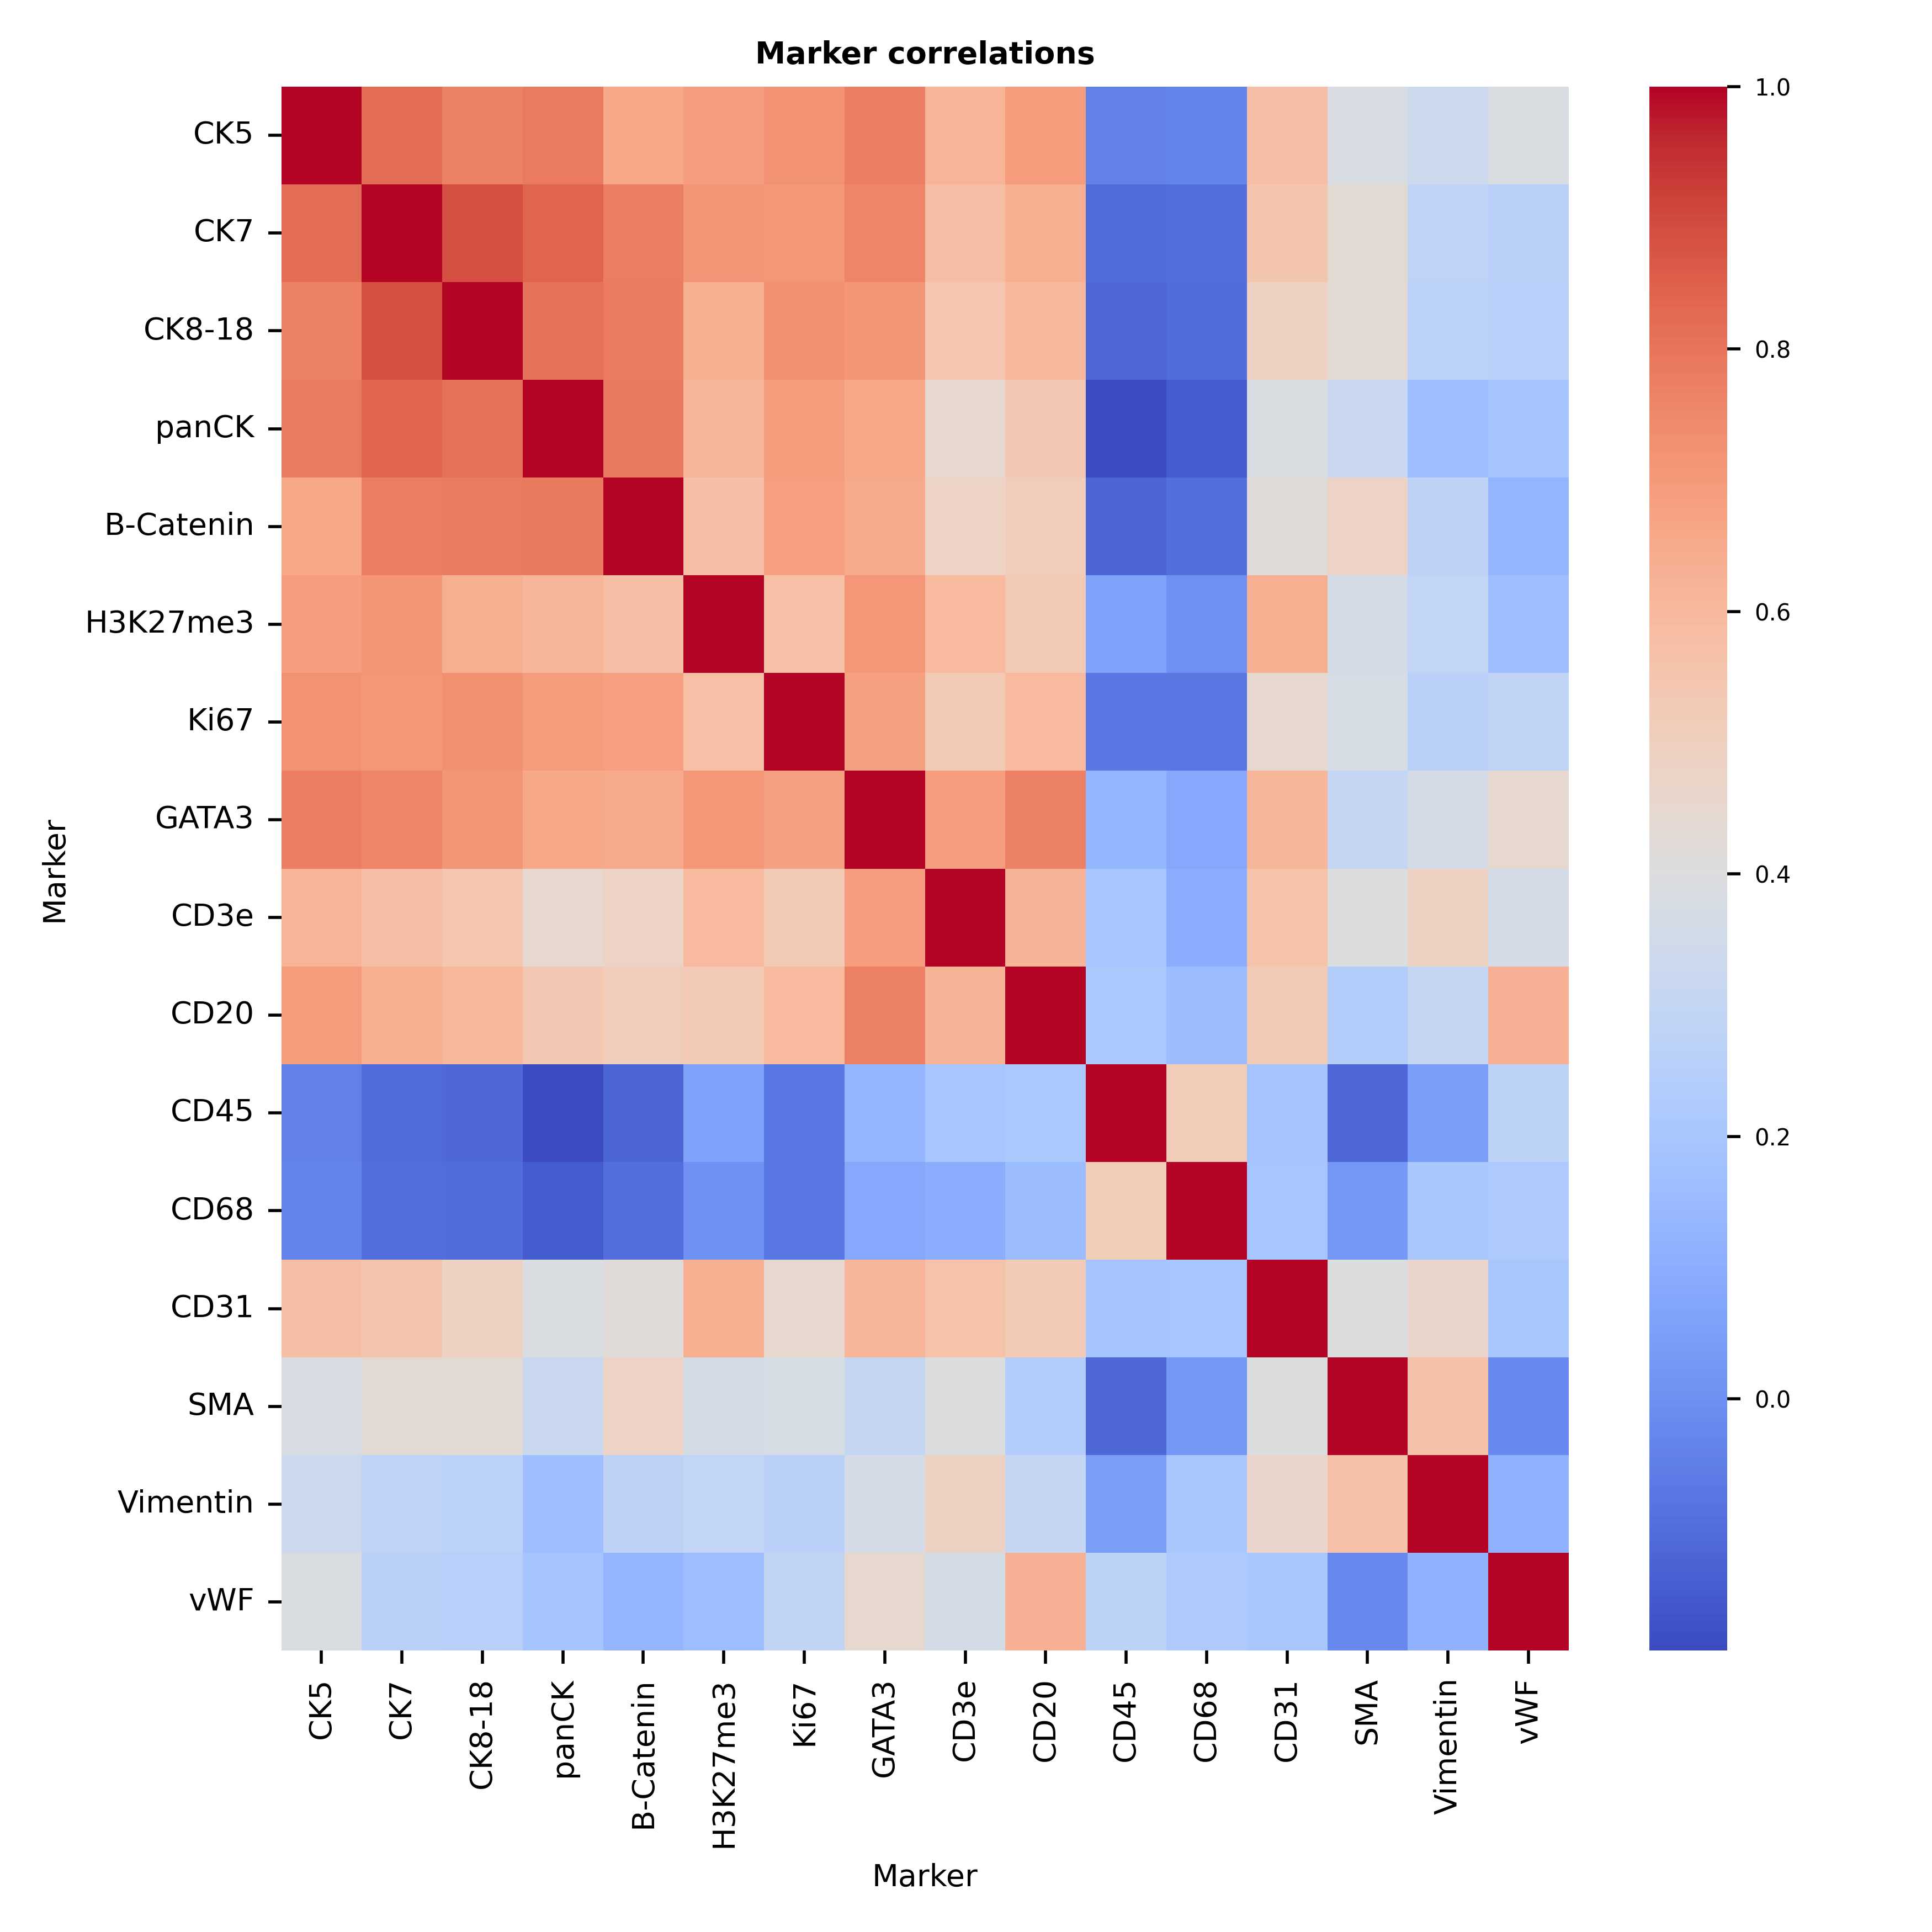

In [6]:
Image(filename=f"{OUT_DIR}/tnbc_exp_marker_correlations_heatmap.png", width=50)

##### Location-based QC metrix

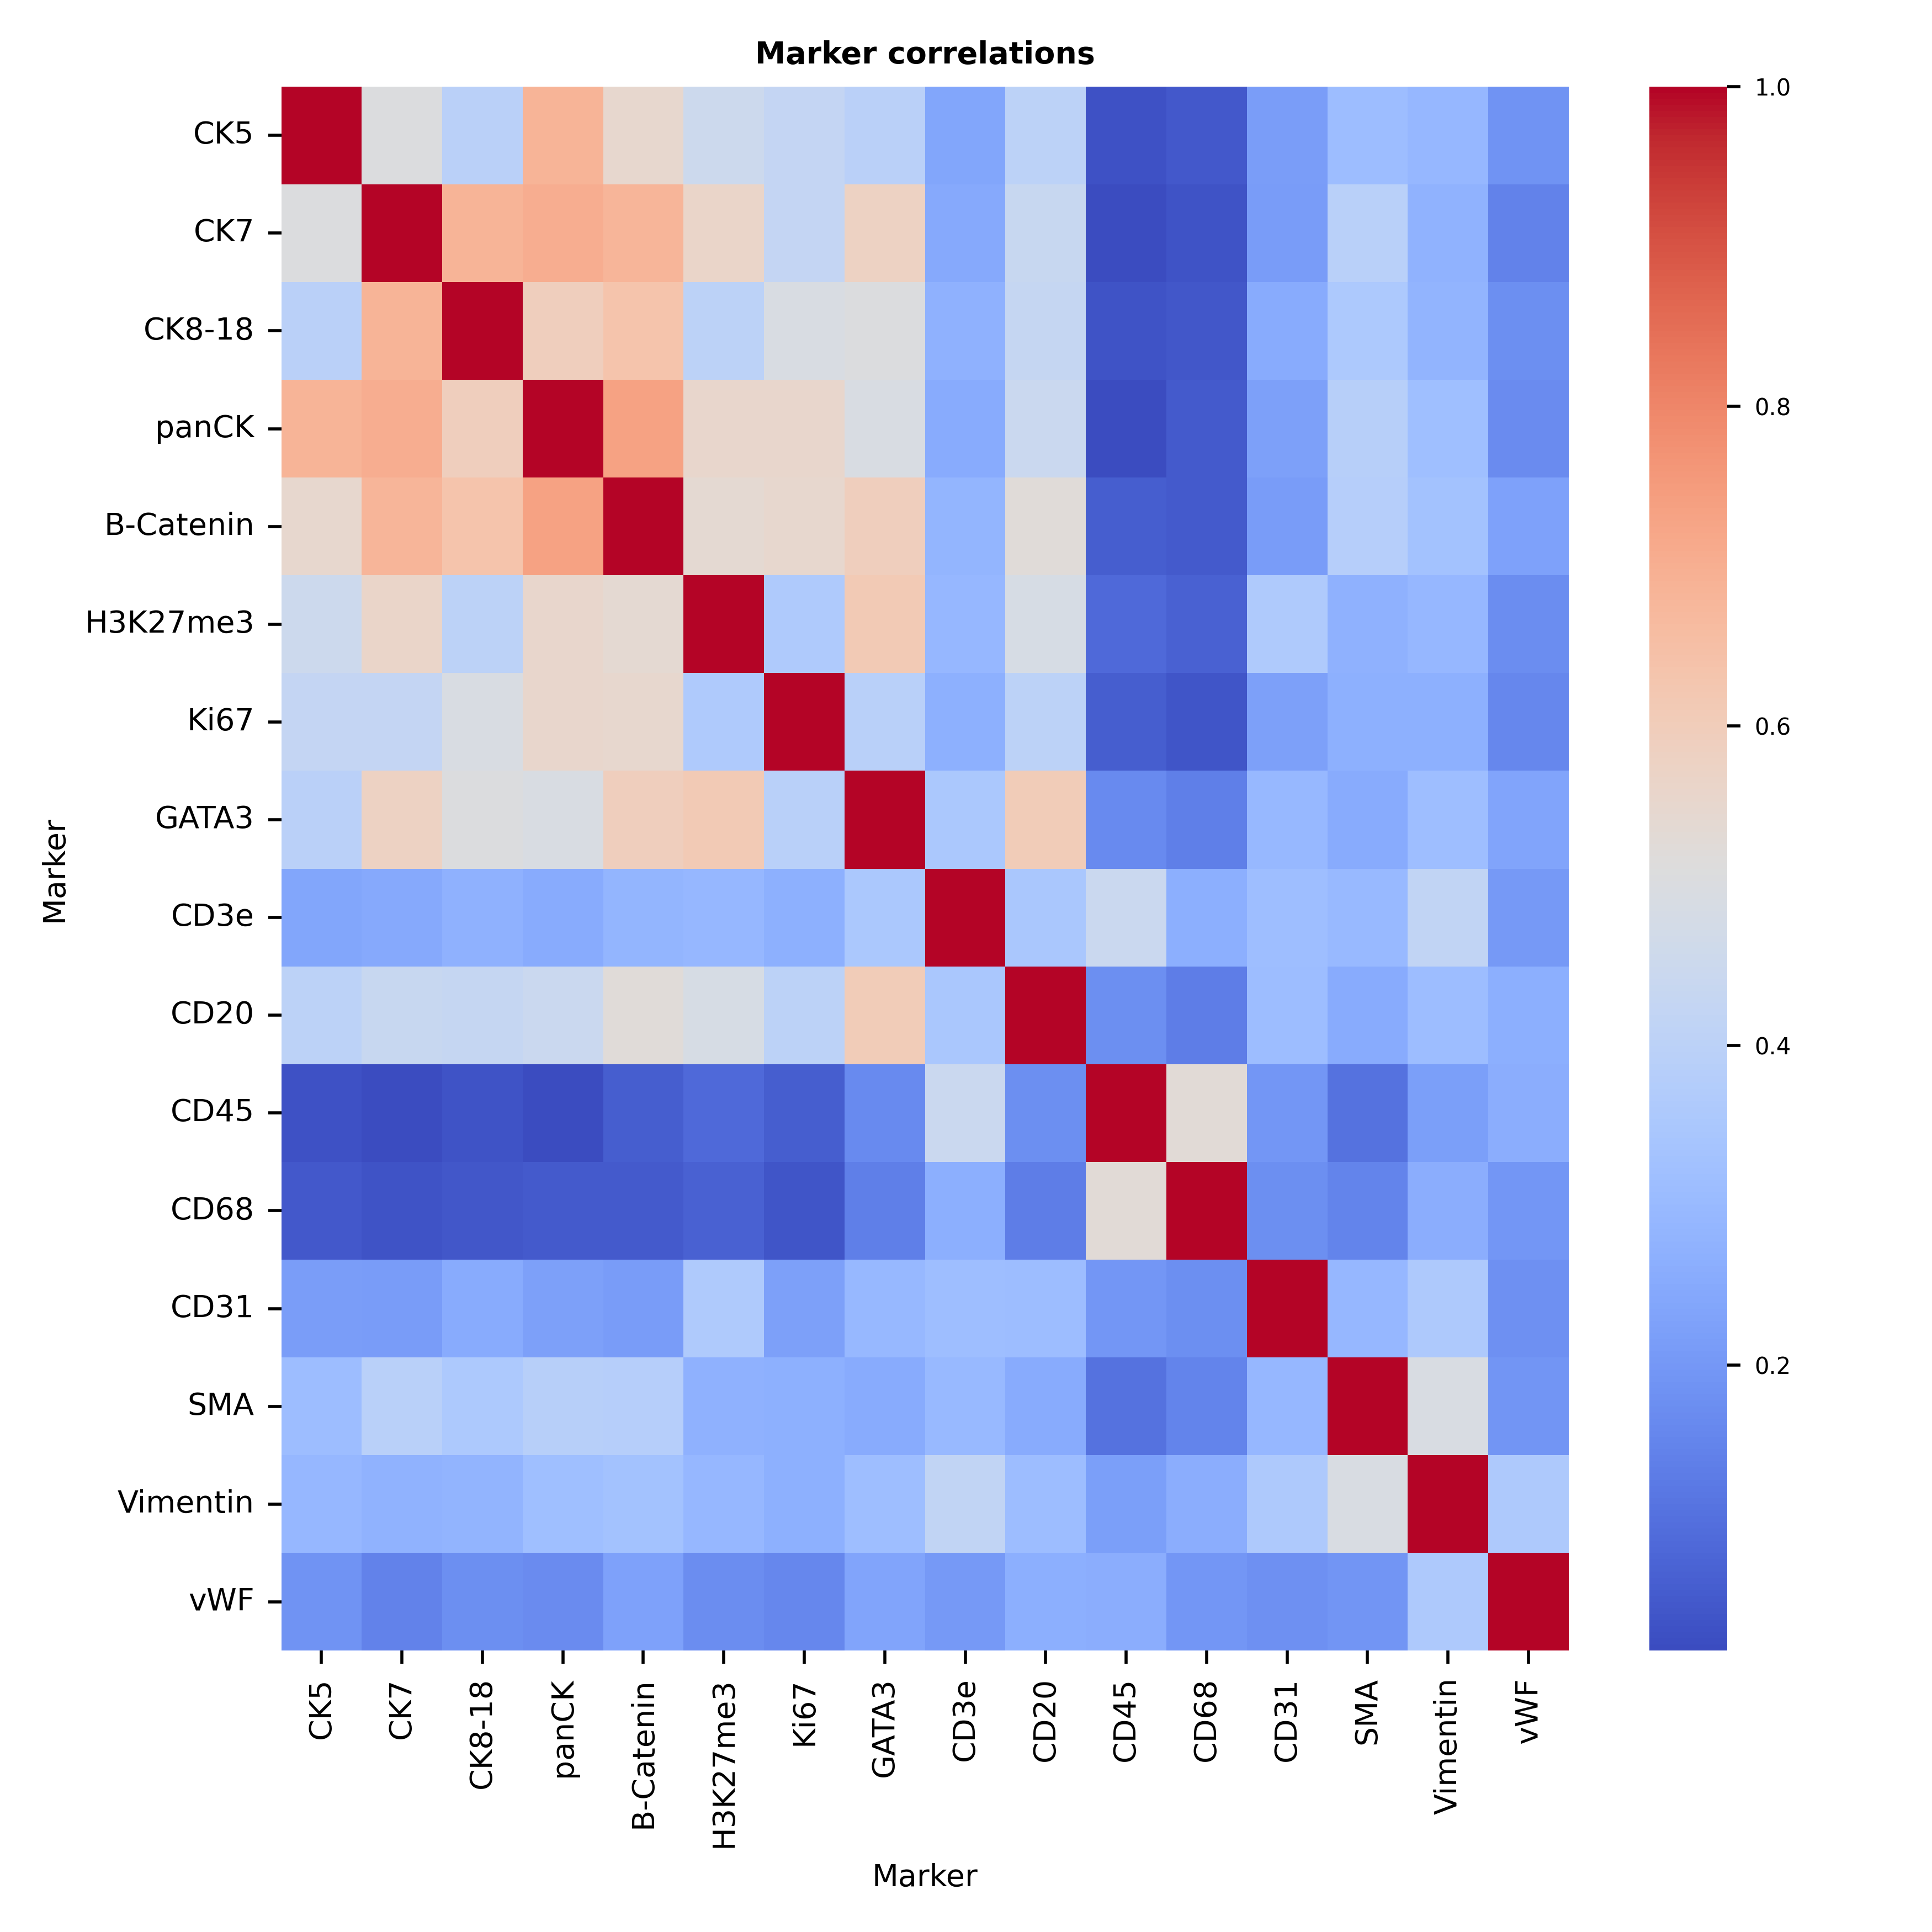

In [7]:
Image(filename=f"{OUT_DIR}/tnbc_loc_marker_correlations_heatmap.png", width=50)

##### Marker quality control metrix

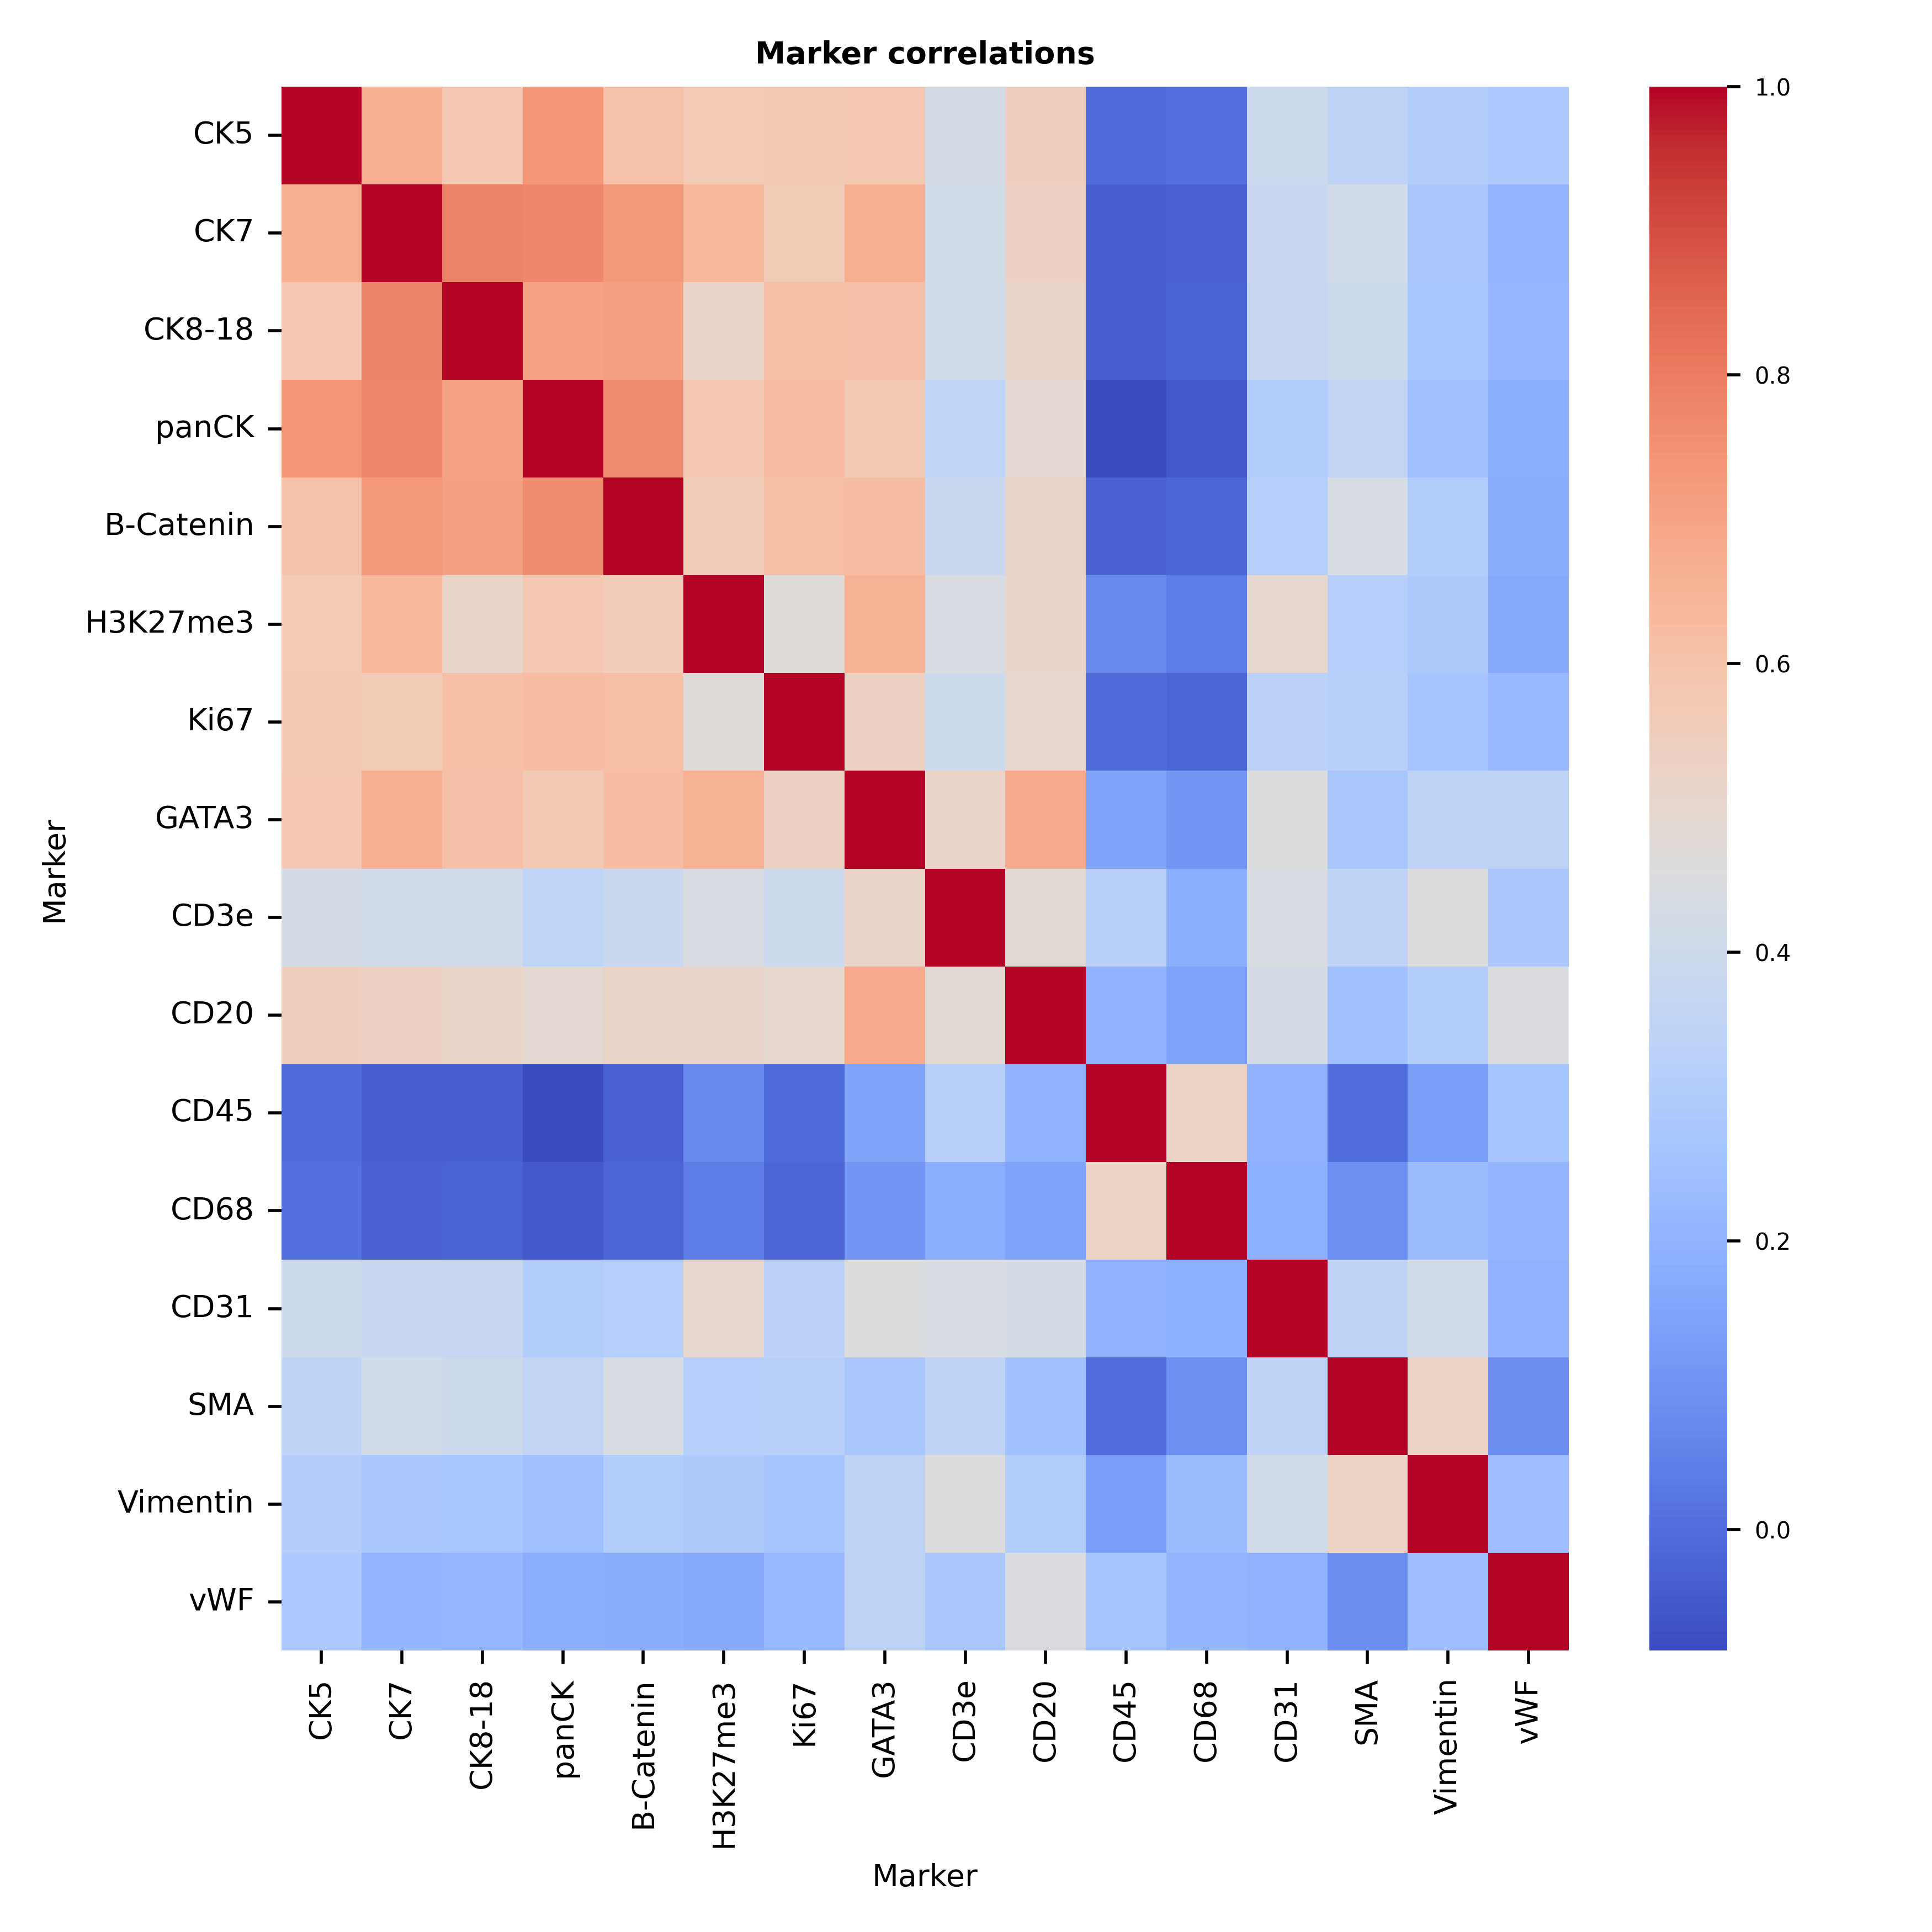

In [8]:
Image(filename=f"{OUT_DIR}/tnbc_marker_correlations_heatmap.png", width=50)

#### Marker-Nuclei staining figures


In [5]:
from marker_quality_control import plot_marker_nuclear_per_image

In [8]:
OUT_DIR = Path(f"output/{EXPERIMENT}/qc/markers")
if os.path.exists(OUT_DIR) == 0:
    os.makedirs(OUT_DIR, exist_ok=True)

NUCLEI = "Nuclei"
plot_marker_nuclear_per_image(marker_list=adata.var_names,
                              nuclei_name=NUCLEI,
                              in_dir=IN_DIR,
                              out_dir=OUT_DIR)

22-010A 22-010A_ROI_032.ome.tiff


TypeError: unhashable type: 'list'

##### Example: panCK staining images
Here's an example of the marker staining images we will get. For 

In [ ]:
Image(filename=f"{OUT_DIR}/", width=50)

### Clustering and cell type annotation


In [9]:
import scanpy as sc
from visualization import plot_zscore_cluster_mean_heatmap

In [10]:
OUT_DIR = Path(f"output/{EXPERIMENT}/clustering")
if os.path.exists(OUT_DIR) == 0:
    os.makedirs(OUT_DIR, exist_ok=True)

METHOD = 'leiden'
MARKER_LIST = ['CK5', 'CK7', 'CK8-18', 'panCK',
               'CD3e', 'CD20', 'CD45', 'CD68',
               'CD31', 'SMA', 'Vimentin']

RESOLUTIONS = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

adata_layer1 = adata[:, MARKER_LIST].copy()
sc.tl.pca(adata_layer1, n_comps=6, svd_solver='arpack')
sc.pp.neighbors(adata_layer1, n_neighbors=15, use_rep='X_pca')

# Grid search for clustering with different resolution
for res in RESOLUTIONS:
    CLUSTER_KEY = f'layer_1_{res:.1f}'
    print(f"Resolution: {res:.1f}")

    sc.tl.leiden(adata_layer1, resolution=res, key_added=CLUSTER_KEY)

    print("Plotting")
    plot_zscore_cluster_mean_heatmap(
        adata=adata_layer1,
        column_names=MARKER_LIST,
        cluster_key=CLUSTER_KEY,
        out_dir=OUT_DIR,
        vmax=3,
        vmin=-1,
        figsize=(7, 7),
        name=f'layer_1_{res:.1f}'
    )


Resolution: 0.5
Plotting
Resolution: 0.6
Plotting
Resolution: 0.7
Plotting
Resolution: 0.8
Plotting
Resolution: 0.9
Plotting
Resolution: 1.0
Plotting


AnnData object with n_obs × n_vars = 22213 × 11
    obs: 'image_id', 'area', 'TMA', 'unique_img_key', 'CID', 'Chemo type', 'pCR', 'Recurrence status', 'collection_type', 'Experiment', 'Core location', 'layer_1_0.5', 'layer_1_0.6', 'layer_1_0.7', 'layer_1_0.8', 'layer_1_0.9', 'layer_1_1.0'
    uns: 'leiden', 'neighbors', 'pca'
    obsm: 'X_pca', 'spatial'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

<Figure size 700x700 with 0 Axes>

<Figure size 700x700 with 0 Axes>

<Figure size 700x700 with 0 Axes>

<Figure size 700x700 with 0 Axes>

<Figure size 700x700 with 0 Axes>

<Figure size 700x700 with 0 Axes>

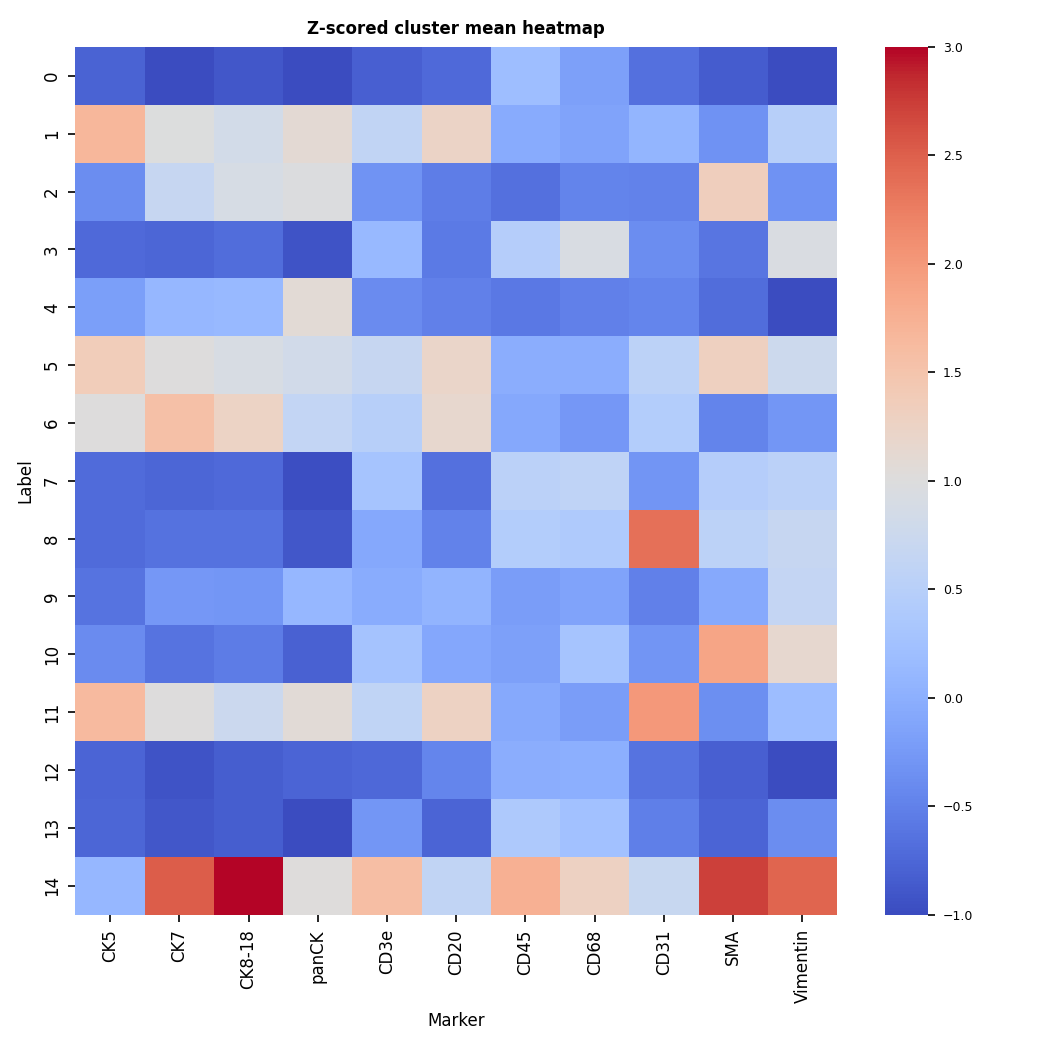

In [11]:
Image(filename=f"{OUT_DIR}/layer_1_0.6_heatmap_z_cluster_mean.png", width=50)

To decide the best parameter (resolution) in clustering, we then use Davies-Bouldin Index (DB-Index) to evaluate clustering performance. The lower score of the resolution, the better clustering result, so we keep the clusters obtained by the resolution with the best performance for the next layer clustering. 

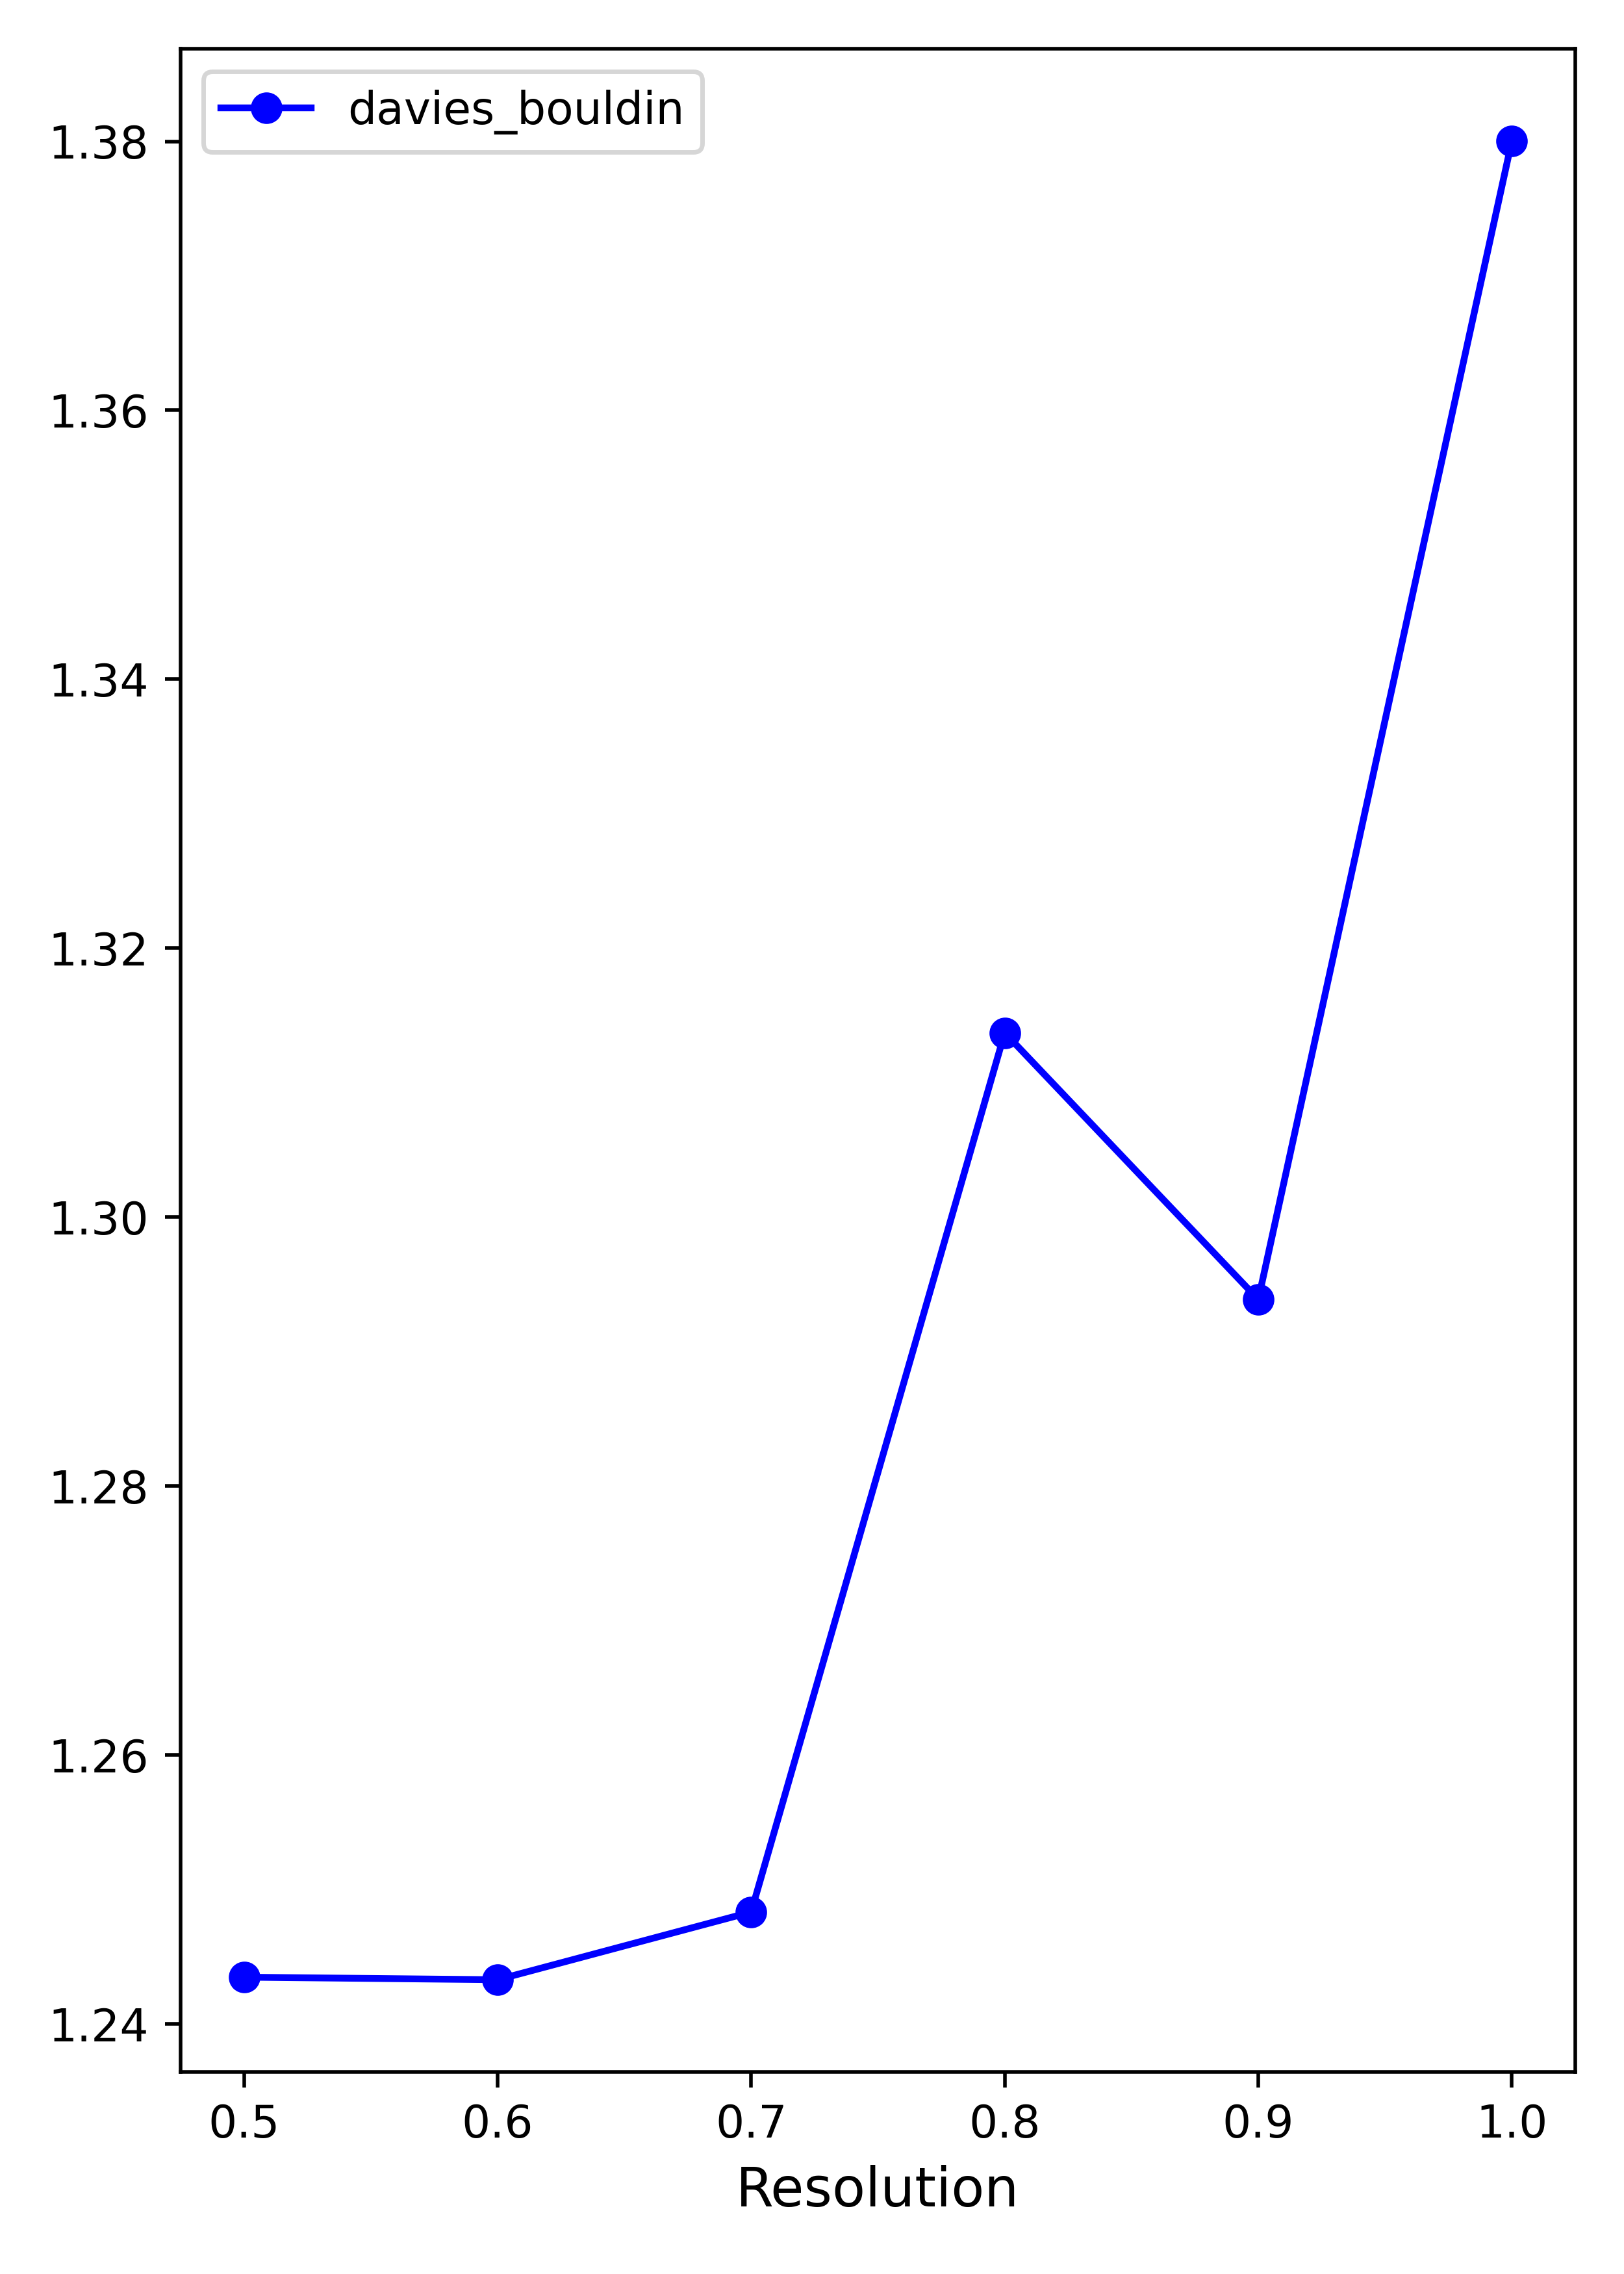

<Figure size 500x700 with 0 Axes>

In [13]:
from clustering import compare_clustering_resolutions
from visualization import plot_compare_clustering_line

METHOD = 'davies_bouldin'
compare_clustering_resolutions(adata=adata_layer1,
                               resolutions=RESOLUTIONS,
                               method=METHOD)

plot_compare_clustering_line(adata=adata_layer1,
                             method=METHOD,
                             out_dir=OUT_DIR,
                             figsize=(7, 5),
                             name="layer_1")

Image(filename=f"{OUT_DIR}/layer_1_clustering_performance.png", width=50)

#### Second-round clustering
Keeping the clustering results with the appropriate resolution, let's annotate each clusters based on the lineage expression into Epithelial, Immune, Stromal or Undefined cell type. To validate our first-layer cell type annotation, a z-score expression heatmap helps us to check the protein expression of certain cell types and a distribution plot helps us to see where does each cell type localizes on the ROI.

In [14]:
from utils import update_labels

In [30]:
# layer 1 cell type annotation
CLUSTER_KEY = 'layer_1_0.6'
esi = ['Immune', 'Epithelial', 'Stromal', 'Immune', 'Epithelial',
       'Epithelial', 'Epithelial', 'Immune', 'Stromal', 'Undefined',
       'Stromal', 'Stromal', 'Immune', 'Immune', 'Undefined']

# Update the labels to Anndata object
esi_map = dict(zip(range(len(esi)), esi))
adata_layer1.obs[CLUSTER_KEY] = adata_layer1.obs[CLUSTER_KEY].astype(int)
update_labels(adata_layer1, "layer_1", [esi_map[i] for i in adata_layer1.obs[CLUSTER_KEY]])
adata.obs["layer_1"] = adata_layer1.obs.layer_1
adata = adata[adata.obs.layer_1 != "Undefined"]

In [33]:
[esi_map[i] for i in adata_layer1.obs[CLUSTER_KEY]][:5]

['Undefined', 'Undefined', 'Immune', 'Immune', 'Undefined']

In [23]:
adata_layer1.obs.layer_1 = adata_layer1.obs[CLUSTER_KEY].astype(int)

set(adata_layer1.obs['layer_1'])

{'Epithelial', 'Immune', 'Stromal', 'Undefined'}

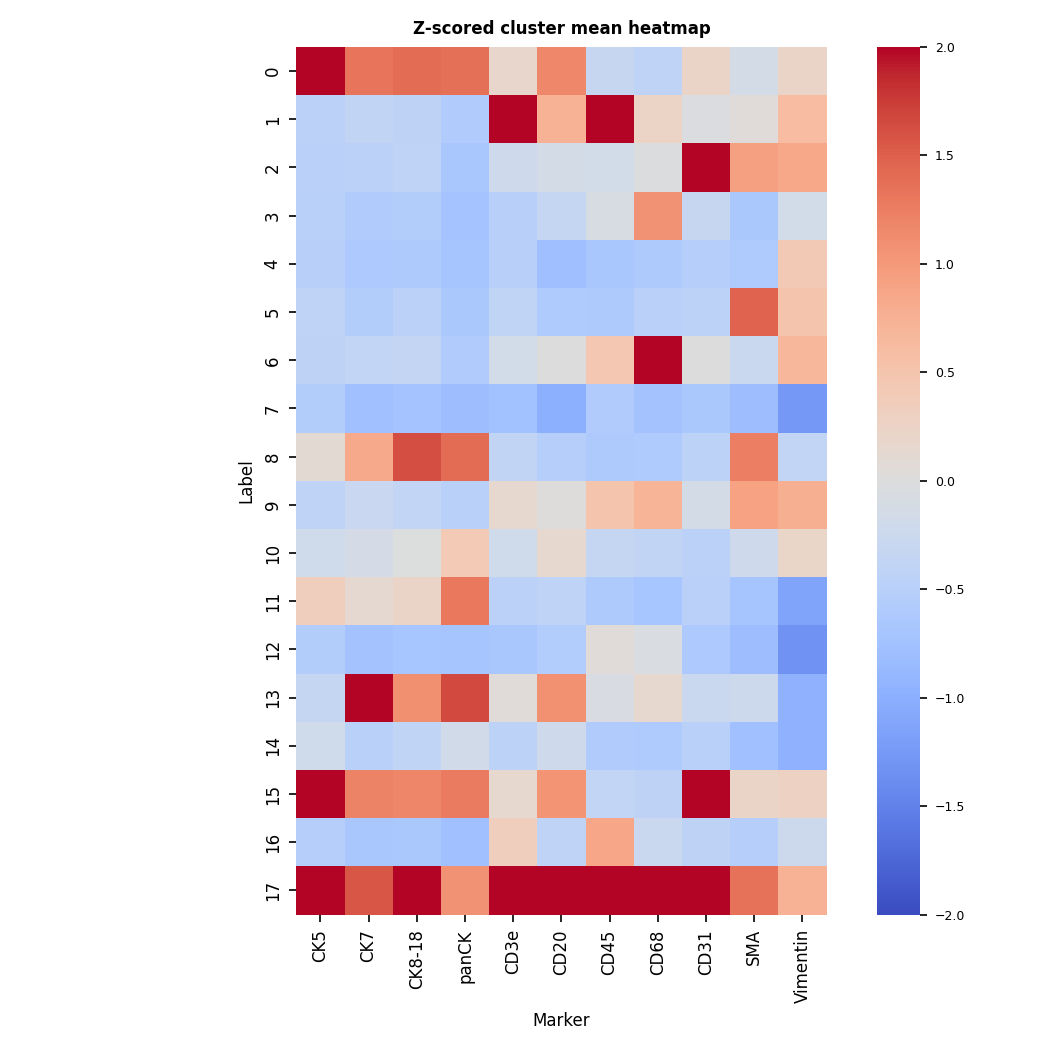

In [24]:
CLUSTER_KEY = "layer_1"
plot_zscore_cluster_mean_heatmap(
    adata=adata,
    column_names=MARKER_LIST,
    cluster_key=CLUSTER_KEY,
    out_dir=OUT_DIR,
    vmax=3,
    vmin=-1,
    figsize=(7, 7),
    name=CLUSTER_KEY
)
Image(filename=f"{OUT_DIR}/layer_1_heatmap_z_cluster_mean.png", width=50)

In [18]:
adata

View of AnnData object with n_obs × n_vars = 22213 × 16
    obs: 'image_id', 'area', 'TMA', 'unique_img_key', 'CID', 'Chemo type', 'pCR', 'Recurrence status', 'collection_type', 'Experiment', 'Core location', 'layer_1_0.5', 'layer_1'
    uns: 'leiden', 'neighbors', 'pca'
    obsm: 'X_pca', 'spatial'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

### Cell type annotation

Two rounds of Leiden clustering was performed here for the low dimension dataset (16 protein markers here as the example).


In the first layer of clustering, we will classify all the cells as epithelial, immune or stromal cells based on the certain markers representing each cell type.
(e.g. panCK for epithelial, CD45 for pan-immune and SMA for stromal)





### Cell niche classification

### Exploratory data analysis (EDA) for distinct cell types and cell niches in different patient groups


In [10]:
adata

AnnData object with n_obs × n_vars = 48140 × 16
    obs: 'image_id', 'area', 'TMA', 'unique_img_key', 'CID', 'Chemo type', 'pCR', 'Recurrence status', 'collection_type', 'Experiment', 'Core location'
    obsm: 'spatial'

In [ ]:
CLUSTER_KEY = "layer_2"






In [34]:
set(adata.obs.unique_img_key)

{'22-010A_ROI_032', '22-010A_ROI_060', '22-010C_ROI_008', '23-009_ROI_006'}

### Cell type distribution and validation
After we got cell type identification, we're going to use several ways of validation.   